# 🖼️ **: Image Data Prep (MNIST)**

Welcome to Image Classification! We are going to use the **MNIST dataset**, which contains 70,000 hand-drawn numbers (0 through 9). Our goal on Day 2 will be to build a Neural Network that can look at these pixels and predict which number was drawn.

### 🔹 **Torchvision & Transforms**
Instead of using Pandas, we use PyTorch's `torchvision` library to download standard image datasets.
We also apply a **Transform** called `ToTensor()`. This does two magical things automatically:
1. Converts the raw image pixels into a PyTorch Tensor.
2. Scales the pixel values from [0 to 255] down to a fair range of **[0.0 to 1.0]** (Built-in Feature Scaling!).

In [ ]:
import torch
from torchvision import datasets, transforms

# Downloading the training and testing data
print("Downloading MNIST Dataset...")

# 1. We define the transformation (Image -> Tensor -> Scaled 0 to 1)
transform = transforms.ToTensor()

# 2. Download the Training Data
train_data = datasets.MNIST(
    root="data",         # Where to save the files
    train=True,          # This is the training set
    download=True,       # Download it if we don't have it
    transform=transform  # Apply our transformation
)

# 3. Download the Testing Data
test_data = datasets.MNIST(
    root="data",
    train=False,         # This is the testing set
    download=True,
    transform=transform
)

print(f"Success! We have {len(train_data)} Training images and {len(test_data)} Testing images.")

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.1MB/s]

Success! We have 60000 Training images and 10000 Testing images.


# 👁️ **Visualizing the Tensors**

A Neural Network just sees a giant grid of decimal numbers. Let's use **Matplotlib** to draw those numbers as an actual image so we can see what the model is learning from.

### ⚠️ **The Shape Problem**
PyTorch stores grayscale images in the shape **[Channels, Height, Width]**, so MNIST images are `[1, 28, 28]`.
However, Matplotlib expects a flat 2D grid `[28, 28]`. We will use our trusty `.squeeze()` method from earlier today to drop that useless '1' channel!

Original PyTorch Image Shape: torch.Size([1, 28, 28])
Squeezed Image Shape: torch.Size([28, 28])



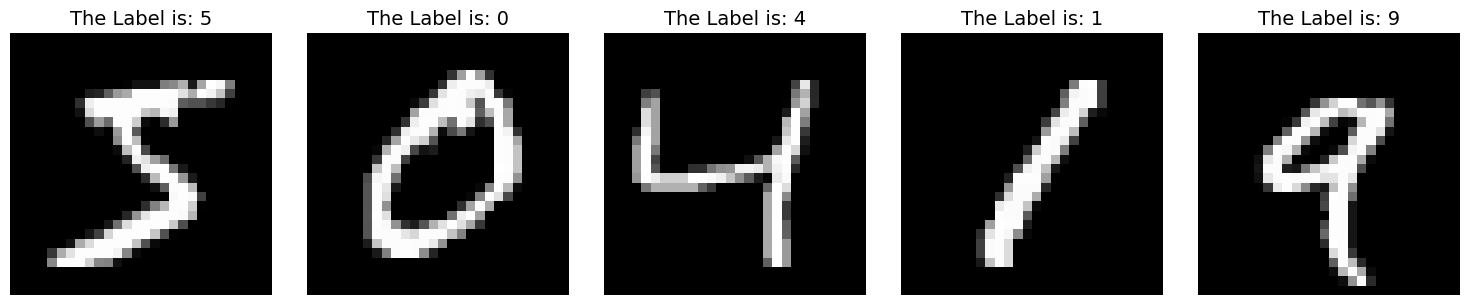

In [ ]:
import matplotlib.pyplot as plt

# Grabbing and plotting the first 5 images from our training data
# Create a blank figure with 1 row and 5 columns
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

# Loop through the first 5 images in the dataset
for i in range(5):
    image, label = train_data[i]

    if i == 0:
        print(f"Original PyTorch Image Shape: {image.shape}") # [1, 28, 28]

    # Squeeze the image to remove the color channel dimension
    clean_image = image.squeeze()

    if i == 0:
        print(f"Squeezed Image Shape: {clean_image.shape}\n")   # [28, 28]

    # Plot the image on its specific subplot
    axes[i].imshow(clean_image, cmap="gray")
    axes[i].set_title(f"The Label is: {label}", fontsize=14)
    axes[i].axis("off") # Hides the grid lines

plt.tight_layout()
plt.show()

# 🚚 **Image DataLoaders**

Just like with our Tabular dataset, we cannot feed 60,000 images into the GPU all at once. It will instantly crash the memory.

We wrap our dataset in a **DataLoader** to feed the images in perfectly sized **Batches**.

In [ ]:
from torch.utils.data import DataLoader

# Creating the Conveyor Belts
BATCH_SIZE = 64

train_loader = DataLoader(dataset=train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(dataset=test_data, batch_size=BATCH_SIZE, shuffle=False)

# Let's inspect ONE batch to see exactly what goes into our Neural Network
# We use iter() and next() to grab the first batch off the conveyor belt
images, labels = next(iter(train_loader))

print(f"Batch Images Shape: {images.shape}")
# Look closely at the shape! [64, 1, 28, 28] -> [Batch_Size, Channels, Height, Width]

print(f"Batch Labels Shape: {labels.shape}")
# [64] -> One answer for each of the 64 images!

Batch Images Shape: torch.Size([64, 1, 28, 28])
Batch Labels Shape: torch.Size([64])


# 🖼️ **Building the Image Classifier**

Now we are going to build a neural network to read handwriting!

### 🔹 **The Differences from our House Model:**
1. **Flattening:** Images are 2D grids (`28x28` pixels). Standard linear layers only accept 1D lists. We have to "flatten" the image into a single row of `784` pixels before feeding it to the network.
2. **Output Layer:** Instead of predicting 1 price, we have 10 possible categories (digits 0 through 9). So, our final layer must output **10 numbers** (the model's confidence for each digit).

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# THE MNIST CLASSIFIER MODEL
class DigitClassifier(nn.Module):
    # We pass the dimensions as parameters, but provide default values just in case!
    def __init__(self, input_dim, output_dim , hidden_dim1=128, hidden_dim2=64):
        super(DigitClassifier, self).__init__()

        self.layer1 = nn.Linear(input_dim, hidden_dim1)
        self.layer2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.output_layer = nn.Linear(hidden_dim2, output_dim)

    def forward(self, x):
        # Step 1: Flatten the 2D image [Batch, 1, 28, 28] into a 1D array [Batch, 784]
        # x.shape[0] dynamically grabs the batch size so it doesn't crash!
        x = x.view(x.shape[0], -1)

        # Step 2: Pass through the hidden layers with ReLU
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))

        # Step 3: Output the raw scores
        x = self.output_layer(x)
        return x

# 🏋️ **Training the Image Model**

The training loop is identical to our house model. The only difference is that we don't need to reshape the labels (`y_batch.view(-1, 1)`) because classification models expect the answers as a simple 1D list.

In [ ]:
from tqdm import tqdm

# TRAIN ONE EPOCH
def train_one_epoch_mnist(model, optimizer, criterion, train_loader, device, epoch_num, total_epochs):
    model.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch_num}/{total_epochs} [TRAIN]", leave=False)

    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)

        # 1. Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # 2. Backward pass & optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    return running_loss / len(train_loader)

# 🧪 **Testing the Image Model (Accuracy!)**

Because we are doing Classification instead of Regression, we can finally calculate real **Accuracy** (e.g., 95% correct).

To do this, we use `torch.max()` to find which of the 10 output scores is the highest. That index (0-9) is our model's official guess!

In [ ]:
# VALIDATE ONE EPOCH
def validate_one_epoch_mnist(model, criterion, test_loader, device, epoch_num, total_epochs):
    model.eval()
    running_val_loss = 0.0

    # We track total correct guesses to calculate standard Accuracy
    correct_guesses = 0
    total_images = 0

    loop = tqdm(test_loader, desc=f"Epoch {epoch_num}/{total_epochs} [VAL]", leave=False)

    with torch.no_grad():
        for images, labels in loop:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_val_loss += loss.item()

            # Calculate Accuracy
            # torch.max returns the highest score. The index is the model's guess!
            _, predicted = torch.max(outputs.data, 1)
            total_images += labels.size(0)
            correct_guesses += (predicted == labels).sum().item()

            # Live update progress bar
            current_acc = (correct_guesses / total_images) * 100
            loop.set_postfix(val_loss=loss.item(), accuracy=f"{current_acc:.2f}%")

    avg_val_loss = running_val_loss / len(test_loader)
    final_accuracy = (correct_guesses / total_images) * 100

    return avg_val_loss, final_accuracy

# ⚙️ **Hyperparameters for Classification**

### ⚠️ **The Big Change: Loss Function**
For houses (Regression), we used Mean Squared Error (MSE).
For images (Classification), we MUST use **CrossEntropyLoss**. This function is mathematically designed specifically to handle category probabilities.

In [ ]:
import torch.optim as optim

# HYPERPARAMETERS & SETUP
# 1. Define Network Dimensions
INPUT_DIM = 28 * 28  # 784 total pixels
HIDDEN_DIM_1 = 128
HIDDEN_DIM_2 = 64
OUTPUT_DIM = 10      # Digits 0 through 9

# 2. Define Training Hyperparameters
EPOCHS = 5
LEARNING_RATE = 0.001

# 3. Hardware target
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware target: {device.type.upper()}")

# 4. Initialize Model, Loss, and Optimizer
# Notice how we pass our dimensions into the model here!
model = DigitClassifier(INPUT_DIM, HIDDEN_DIM_1, HIDDEN_DIM_2, OUTPUT_DIM).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("MNIST Classifier, CrossEntropyLoss, and Optimizer perfectly initialized!")

Hardware target: CUDA
MNIST Classifier, CrossEntropyLoss, and Optimizer perfectly initialized!


# 🚀 **Executing the MNIST Training Loop**

Let's run the loop! Watch the Validation Accuracy climb as the model slowly learns how to read the different variations of human handwriting.

In [ ]:
# EXECUTE THE TRAINING LOOP
train_losses = []
val_losses = []
val_accuracies = []

print("🚀 Starting MNIST Training...\n")

for epoch in range(1, EPOCHS + 1):

    # Run Training Phase
    train_loss = train_one_epoch_mnist(model, optimizer, criterion, train_loader, device, epoch, EPOCHS)
    train_losses.append(train_loss)

    # Run Validation Phase
    val_loss, val_acc = validate_one_epoch_mnist(model, criterion, test_loader, device, epoch, EPOCHS)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Print Summary
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Accuracy: {val_acc:.2f}%")

print("\n🎉 MNIST Training Complete!")

🚀 Starting MNIST Training...



Epoch 01/5 | Train Loss: 0.7678 | Val Loss: 0.3169 | Accuracy: 90.82%


Epoch 02/5 | Train Loss: 0.2572 | Val Loss: 0.2111 | Accuracy: 93.84%


Epoch 03/5 | Train Loss: 0.1953 | Val Loss: 0.1782 | Accuracy: 94.72%


Epoch 04/5 | Train Loss: 0.1627 | Val Loss: 0.1533 | Accuracy: 95.51%


Epoch 05/5 | Train Loss: 0.1403 | Val Loss: 0.1435 | Accuracy: 95.69%

🎉 MNIST Training Complete!


# 📈 **Plotting the Results**

We will plot the Loss Curve just like before, but instead of plotting "Dollar Error", we will plot our official Accuracy percentage!

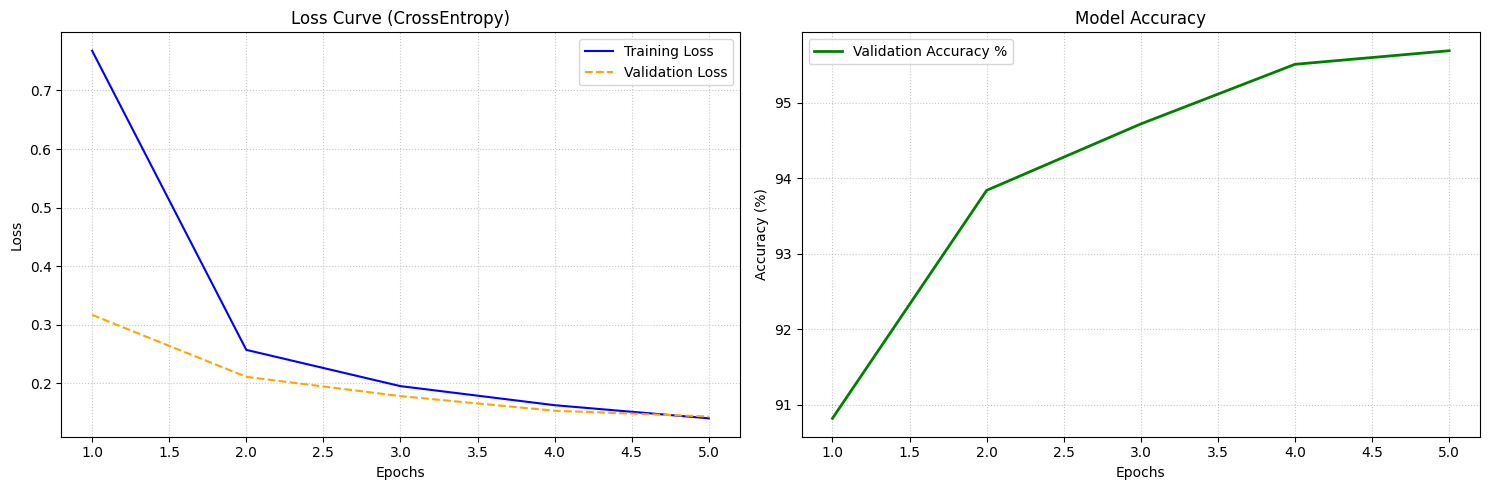

In [ ]:
import matplotlib.pyplot as plt

# PLOT LEARNING & ACCURACY CURVES
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: The Loss Curves
axes[0].plot(range(1, EPOCHS + 1), train_losses, label='Training Loss', color='blue')
axes[0].plot(range(1, EPOCHS + 1), val_losses, label='Validation Loss', color='orange', linestyle='--')
axes[0].set_title('Loss Curve (CrossEntropy)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.7)

# Plot 2: The Accuracy Curve
axes[1].plot(range(1, EPOCHS + 1), val_accuracies, label='Validation Accuracy %', color='green', linewidth=2)
axes[1].set_title('Model Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# 🎯 **Visualizing the Predictions**

Numbers are great, but let's see exactly what the model is looking at. We will grab 5 random images from the test set, show them to the model, and plot its guess alongside the true answer!

/tmp/ipykernel_1964/2266170523.py:52: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1964/2266170523.py:52: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


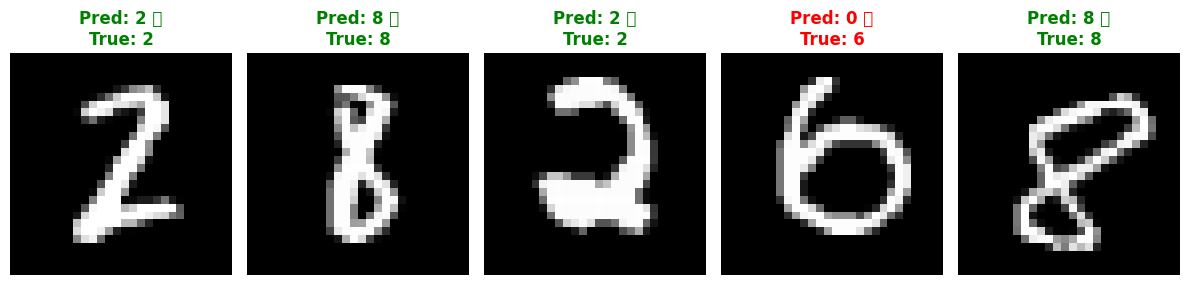

In [ ]:
# VISUALIZE 5 PREDICTIONS
# Set model to evaluation mode
model.eval()

# Grab one batch of test data
dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = next(dataiter)
images, labels = next(dataiter)
images, labels = next(dataiter)
images, labels = next(dataiter)
images_device = images.to(device)

# Ask the model to guess what they are
with torch.no_grad():
    outputs = model(images_device)
    _, predicted = torch.max(outputs, 1)

# Move data back to CPU and convert to numpy for Matplotlib
images = images.numpy()
predicted = predicted.cpu().numpy()
labels = labels.numpy()

# Create a clean 1x5 grid (1 row, 5 columns)
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

# Loop through the first 5 images in our batch
for i in range(5):
    # Squeeze the image from [1, 28, 28] down to [28, 28]
    img = images[i].squeeze()

    # Plot the image on its specific subplot
    axes[i].imshow(img, cmap='gray')

    # Check if the model got it right to set the text color
    if predicted[i] == labels[i]:
        text_color = "green"
        status = "✅"
    else:
        text_color = "red"
        status = "❌"

    # Add a title with the Guess and the True Answer
    axes[i].set_title(f"Pred: {predicted[i]} {status}\nTrue: {labels[i]}",
                      color=text_color,
                      fontweight='bold',
                      fontsize=12)

    # Hide the axis lines for a cleaner look
    axes[i].axis('off')

plt.tight_layout()
plt.show()